In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv('/content/telco.csv')
df.shape

(7043, 50)

In [3]:
df.columns.tolist()

['Customer ID',
 'Gender',
 'Age',
 'Under 30',
 'Senior Citizen',
 'Married',
 'Dependents',
 'Number of Dependents',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Latitude',
 'Longitude',
 'Population',
 'Quarter',
 'Referred a Friend',
 'Number of Referrals',
 'Tenure in Months',
 'Offer',
 'Phone Service',
 'Avg Monthly Long Distance Charges',
 'Multiple Lines',
 'Internet Service',
 'Internet Type',
 'Avg Monthly GB Download',
 'Online Security',
 'Online Backup',
 'Device Protection Plan',
 'Premium Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Streaming Music',
 'Unlimited Data',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charge',
 'Total Charges',
 'Total Refunds',
 'Total Extra Data Charges',
 'Total Long Distance Charges',
 'Total Revenue',
 'Satisfaction Score',
 'Customer Status',
 'Churn Label',
 'Churn Score',
 'CLTV',
 'Churn Category',
 'Churn Reason']

In [4]:
columns_to_drop = [
    'Customer ID', 'Country', 'State',
    'Customer Status', 'Churn Category', 'Churn Reason',
    'Churn Score', 'Satisfaction Score', 'CLTV',
    'Total Revenue', 'Total Charges', 'Total Long Distance Charges', 'Referred a Friend'
]
df_cleaned = df.drop(columns=columns_to_drop, errors='ignore')
df_cleaned.shape

(7043, 37)

In [5]:
df_cleaned['Offer'] = df_cleaned['Offer'].fillna('None')
df_cleaned['Internet Type'] = df_cleaned['Internet Type'].fillna('None')
df_cleaned.isnull().sum().sum()

np.int64(0)

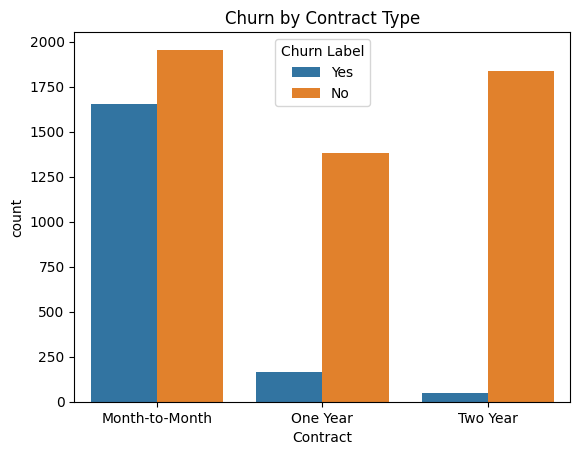

In [6]:
sns.countplot(data=df_cleaned, x='Contract', hue='Churn Label')
plt.title('Churn by Contract Type')
plt.show()

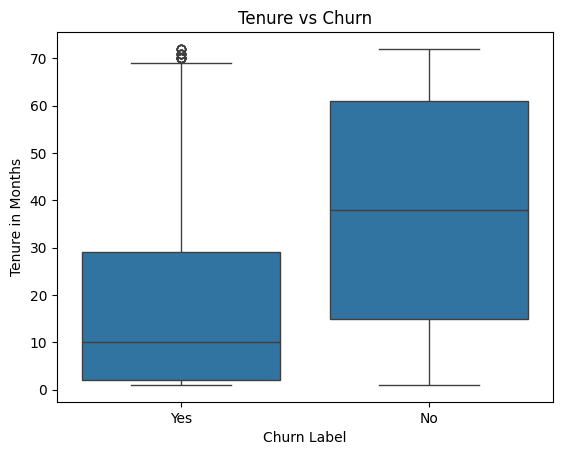

In [7]:
sns.boxplot(data=df_cleaned, x='Churn Label', y='Tenure in Months')
plt.title('Tenure vs Churn')
plt.show()

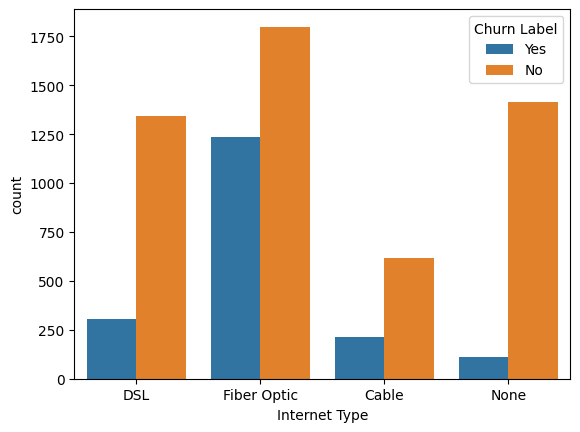

In [8]:
sns.countplot(data=df_cleaned, x='Internet Type', hue='Churn Label')
plt.show()

In [9]:
y = df_cleaned['Churn Label'].map({'Yes': 1, 'No': 0})
X_raw = df_cleaned.drop(columns=['Churn Label', 'City', 'Zip Code', 'Latitude', 'Longitude'], errors='ignore')
X = pd.get_dummies(X_raw, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(5634, 39) (1409, 39)


In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
lr = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr.fit(X_train_scaled, y_train)

rf = RandomForestClassifier(random_state=42, n_estimators=200, class_weight='balanced')
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [12]:
print("Logistic Regression")
print(classification_report(y_test, lr.predict(X_test_scaled)))
print("ROC-AUC:", roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]))

print("Random Forest")
print(classification_report(y_test, rf.predict(X_test)))
print("ROC-AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

Logistic Regression
              precision    recall  f1-score   support

           0       0.94      0.78      0.85      1035
           1       0.59      0.87      0.70       374

    accuracy                           0.80      1409
   macro avg       0.76      0.82      0.78      1409
weighted avg       0.85      0.80      0.81      1409

ROC-AUC: 0.9057506006355112
Random Forest
              precision    recall  f1-score   support

           0       0.86      0.93      0.89      1035
           1       0.75      0.57      0.65       374

    accuracy                           0.84      1409
   macro avg       0.80      0.75      0.77      1409
weighted avg       0.83      0.84      0.83      1409

ROC-AUC: 0.9026156707742387


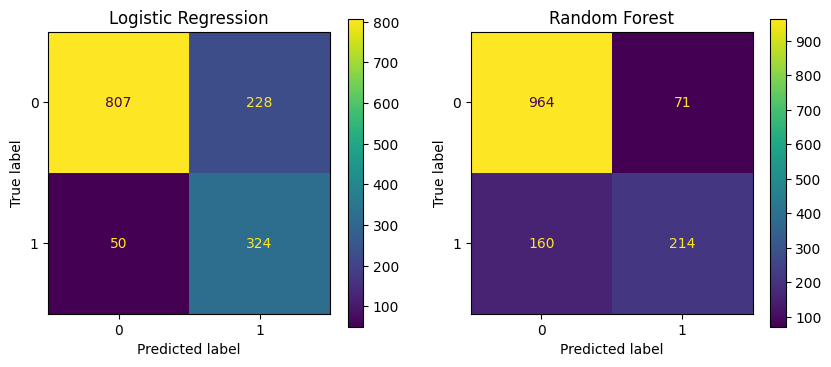

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(lr, X_test_scaled, y_test, ax=ax[0])
ax[0].set_title('Logistic Regression')
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, ax=ax[1])
ax[1].set_title('Random Forest')
plt.show()

In [14]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
print("Logistic Regression CV AUC:", cross_val_score(lr_pipe, X, y, cv=5, scoring='roc_auc').mean())
print("Random Forest CV AUC:", cross_val_score(rf, X, y, cv=5, scoring='roc_auc').mean())

Logistic Regression CV AUC: 0.8952138326545563
Random Forest CV AUC: 0.8890565387753678


In [15]:
odds = pd.Series(np.exp(lr.coef_[0]), index=X.columns).sort_values(ascending=False)
print("Factors that INCREASE churn odds:")
print(odds.head(10))
print("\nFactors that DECREASE churn odds:")
print(odds.tail(10))

Factors that INCREASE churn odds:
Monthly Charge                 7.724011
Married_Yes                    2.242825
Offer_Offer A                  1.284591
Internet Type_None             1.230063
Streaming Music_Yes            1.226851
Senior Citizen_Yes             1.213027
Population                     1.170210
Paperless Billing_Yes          1.166830
Payment Method_Mailed Check    1.124124
Offer_Offer E                  1.092679
dtype: float64

Factors that DECREASE churn odds:
Premium Tech Support_Yes     0.780437
Online Security_Yes          0.769584
Streaming Movies_Yes         0.697230
Phone Service_Yes            0.608401
Internet Type_Fiber Optic    0.565156
Tenure in Months             0.550124
Contract_One Year            0.544341
Dependents_Yes               0.511636
Contract_Two Year            0.294424
Number of Referrals          0.215197
dtype: float64


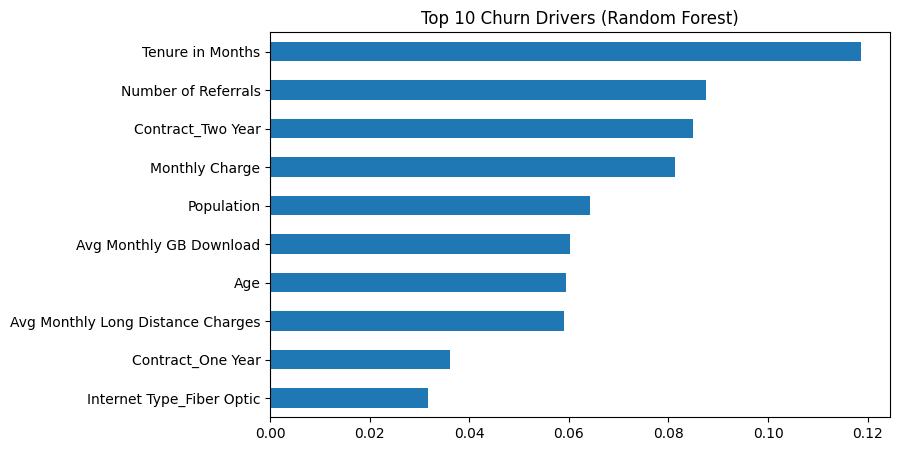

In [16]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.plot(kind='barh', figsize=(8, 5))
plt.gca().invert_yaxis()
plt.title('Top 10 Churn Drivers (Random Forest)')
plt.show()

In [17]:
proba = lr.predict_proba(X_test_scaled)[:, 1]
test_info = df_cleaned.loc[X_test.index, ['Monthly Charge']].copy()
test_info['churned'] = y_test
test_info['proba'] = proba

offer_cost = 50
save_rate = 0.30
months = 12

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flagged = test_info[test_info['proba'] >= t]
    caught = flagged[flagged['churned'] == 1]
    revenue_saved = caught['Monthly Charge'].sum() * months * save_rate
    cost = len(flagged) * offer_cost
    rows.append([t, len(flagged), len(caught), round(revenue_saved), cost, round(revenue_saved - cost)])

pd.DataFrame(rows, columns=['Threshold', 'Flagged', 'Real churners caught', 'Revenue saved $', 'Offer cost $', 'Net benefit $'])

,Threshold,Flagged,Real churners caught,Revenue saved $,Offer cost $,Net benefit $
0,0.3,708,353,94695,35400,59295
1,0.4,640,342,91823,32000,59823
2,0.5,552,324,87409,27600,59809
3,0.6,462,295,80295,23100,57195
4,0.7,362,260,72212,18100,54112
5,0.8,263,208,59694,13150,46544


In [18]:
df_cleaned.groupby('Married')['Churn Label'].apply(lambda s: (s == 'Yes').mean())

,Churn Label
Married,
No,0.329580
Yes,0.196649


In [19]:
X_nm = X.drop(columns=['Monthly Charge'])
X_tr, X_te, y_tr, y_te = train_test_split(X_nm, y, test_size=0.2, random_state=42, stratify=y)
sc2 = StandardScaler()
lr2 = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr2.fit(sc2.fit_transform(X_tr), y_tr)
print("AUC without Monthly Charge:", roc_auc_score(y_te, lr2.predict_proba(sc2.transform(X_te))[:, 1]))
odds2 = pd.Series(np.exp(lr2.coef_[0]), index=X_nm.columns).sort_values(ascending=False)
print(odds2.head(8))
print(odds2.tail(8))

AUC without Monthly Charge: 0.9027099640910381
Married_Yes                  2.255226
Offer_Offer A                1.289613
Streaming Music_Yes          1.235919
Senior Citizen_Yes           1.233608
Internet Type_Fiber Optic    1.194347
Internet Service_Yes         1.191514
Streaming TV_Yes             1.174994
Population                   1.167737
dtype: float64
Offer_Offer D                 0.855841
Internet Type_None            0.839268
Payment Method_Credit Card    0.807754
Tenure in Months              0.552663
Contract_One Year             0.537585
Dependents_Yes                0.509656
Contract_Two Year             0.287259
Number of Referrals           0.213413
dtype: float64


In [20]:
import joblib
joblib.dump(lr, 'churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'columns.pkl')

['columns.pkl']

In [21]:
joblib.dump(X.astype(float).median(), 'defaults.pkl')
import sklearn
print(sklearn.__version__)

1.6.1
